# Regresión logística — predicción de `opinion`

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. Regresión logística: baseline y búsqueda de hiperparámetros
5. Análisis del modelo elegido
6. Submission y resultado en Kaggle

## 1. Carga de datos

In [2]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Regresion_Logistica'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

ModuleNotFoundError: No module named 'numpy'

## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos, así la comparación entre modelos es justa. El motivo de cada decisión está detallado en `Arbol_Clasificacion.ipynb` (sección 2); acá va el resumen.

**Capa 1: limpieza fija (`limpiar`).** Transformaciones que no aprenden nada de los datos:

- `budget` y `revenue`: los 0 y los valores < 1000 pasan a NaN, y se agrega un indicador `*_desconocido`.
- `runtime`: los 0 pasan a NaN.
- `budget`, `revenue`, `vote_count` y `popularity`: `log1p`.
- Variables nuevas: `anio` y `mes` (de `release_date`), `log_roi`, `sin_keywords` y `cant_keywords`.
- Se descartan `status`, `original_title` y `overview`.

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Lo que *aprende* de los datos se ajusta solo con el train de cada fold:

- Numéricas: imputación por mediana + `StandardScaler`.
- `main_genre_top10` y `original_language`: one-hot (los idiomas con menos de 20 películas se agrupan).
- `director` no se usa (no mejoró el AUC del árbol).

**Qué cambia respecto del árbol.** Al árbol casi no le afecta cómo están representadas las variables; a la regresión logística sí:

- **Estandarización:** la regularización penaliza a todos los coeficientes por igual, así que las variables tienen que estar en la misma escala. Además permite comparar los coeficientes entre sí.
- **`log1p`:** el modelo supone que cada variable tiene un efecto lineal. Sin el logaritmo, unas pocas películas con montos enormes dominarían el ajuste.
- **One-hot:** un género o un idioma no tienen orden, así que cada categoría recibe su propio coeficiente.
- **Imputación + indicadores:** la regresión logística no acepta NaN. El indicador `*_desconocido` le permite distinguir "dato desconocido" de "valor igual a la mediana".

## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

## 4. Regresión logística

La regresión logística calcula una suma ponderada de las variables (un coeficiente por variable más una constante) y la convierte, con la función sigmoide, en una probabilidad entre 0 y 1 de que la opinión sea positiva. Es un modelo **lineal**: cada variable empuja la predicción siempre en el mismo sentido y con la misma fuerza, sin importar el valor de las demás.

### 4.1 Baseline

Regresión logística con los hiperparámetros por defecto de sklearn (regularización L2 con `C = 1`). Sirve como punto de partida para medir cuánto aportan los hiperparámetros.

In [ ]:
from sklearn.linear_model import LogisticRegression

baseline = evaluar(LogisticRegression(), X, y, C=1.0, regularizacion='l2')

COLS_TABLA = ['C', 'regularizacion',
              'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']
pd.DataFrame([baseline])[COLS_TABLA].round(3)

,C,regularizacion,auc,auc_std,auc_train,accuracy,precision,recall,f1
0,1.0,l2,0.815,0.009,0.821,0.745,0.751,0.722,0.736


Con los valores por defecto ya alcanza un **AUC de 0,815 en validación contra 0,821 en train**. A diferencia del árbol baseline (1,00 en train y 0,667 en validación), casi no hay distancia entre train y validación: el modelo tiene solo 27 coeficientes para 3602 películas, así que no puede memorizar. Además, ya supera al árbol ajustado (0,769).

### 4.2 Búsqueda de hiperparámetros (grid search)

Se prueban **todas las combinaciones** de:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `C` | 0,001, 0,01, 0,1, 1, 10, 100 | Inversa de la fuerza de la regularización: cuanto más chico, más se penalizan los coeficientes grandes y más simple es el modelo. Es el control del sobreajuste. |
| regularización | L1, L2 | Tipo de penalización. L2 achica todos los coeficientes; L1 puede llevar algunos exactamente a cero, o sea que descarta variables. |

Son 6 × 2 = **12 combinaciones**, cada una evaluada con la misma CV de 5 folds. La tabla completa se guarda en `resultados/Regresion_Logistica/logistica_grilla.csv`. Se usa el solver `liblinear` porque admite los dos tipos de regularización.

In [ ]:
import inspect
import itertools
import warnings
from sklearn.exceptions import UndefinedMetricWarning

# Con la regularización más fuerte el modelo predice una sola clase y la precision no se puede
# calcular (sklearn la deja en 0 y avisa). Es esperado, así que se oculta ese aviso.
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)

# sklearn >= 1.8 reemplazó `penalty` por `l1_ratio` (1 = L1, 0 = L2); Colab usa una versión anterior.
USA_L1_RATIO = inspect.signature(LogisticRegression).parameters['penalty'].default == 'deprecated'

def crear_logistica(C, regularizacion):
    # Regresión logística con regularización 'l1' o 'l2', en cualquier versión de sklearn
    if USA_L1_RATIO:
        return LogisticRegression(C=C, l1_ratio=1.0 if regularizacion == 'l1' else 0.0,
                                  solver='liblinear', random_state=SEED)
    return LogisticRegression(C=C, penalty=regularizacion, solver='liblinear', random_state=SEED)

GRILLA = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'regularizacion': ['l1', 'l2'],
}

filas = []
for C, regularizacion in itertools.product(*GRILLA.values()):
    filas.append(evaluar(crear_logistica(C, regularizacion), X, y, C=C, regularizacion=regularizacion))

grilla = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)

grilla.to_csv(f'{CARPETA_RESULTADOS}/logistica_grilla.csv', index=False)
print(f'{len(grilla)} combinaciones evaluadas')

12 combinaciones evaluadas


**Las 12 combinaciones** (ordenadas por AUC de validación), comparadas con el baseline:

In [ ]:
tabla = grilla[COLS_TABLA].copy()
tabla.index = range(1, len(tabla) + 1)
tabla.loc['baseline'] = pd.Series(baseline)[COLS_TABLA]
tabla.round(3)

,C,regularizacion,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,1.000,l2,0.815,0.009,0.821,0.744,0.751,0.721,0.736
2,1.000,l1,0.815,0.009,0.821,0.743,0.750,0.722,0.735
3,10.000,l2,0.815,0.009,0.821,0.744,0.750,0.721,0.735
4,100.000,l2,0.815,0.009,0.821,0.744,0.750,0.722,0.736
5,100.000,l1,0.815,0.009,0.821,0.744,0.750,0.722,0.735
6,10.000,l1,0.815,0.009,0.821,0.744,0.750,0.722,0.736
7,0.100,l2,0.814,0.009,0.819,0.739,0.748,0.711,0.729
8,0.100,l1,0.812,0.010,0.815,0.745,0.754,0.718,0.735
9,0.010,l2,0.799,0.012,0.802,0.735,0.752,0.693,0.721
10,0.001,l2,0.768,0.017,0.770,0.703,0.716,0.663,0.688


### 4.3 Efecto de la regularización

- **Izquierda:** AUC en train y en validación según `C`, con regularización L2. Con mucha regularización (`C = 0,001`) el modelo queda demasiado simple y rinde menos (0,768). Desde `C = 1` las dos curvas quedan planas en 0,815 (validación) y 0,821 (train): aflojar la regularización no mejora ni genera sobreajuste, al revés de lo que pasaba con la profundidad del árbol.
- **Derecha:** AUC de validación según `C` para L1 y L2. L1 es más sensible a la regularización fuerte: con `C = 0,001` todos los coeficientes quedan en cero y el modelo predice lo mismo para todas las películas (AUC de 0,50). Desde `C = 1` las dos dan el mismo resultado.

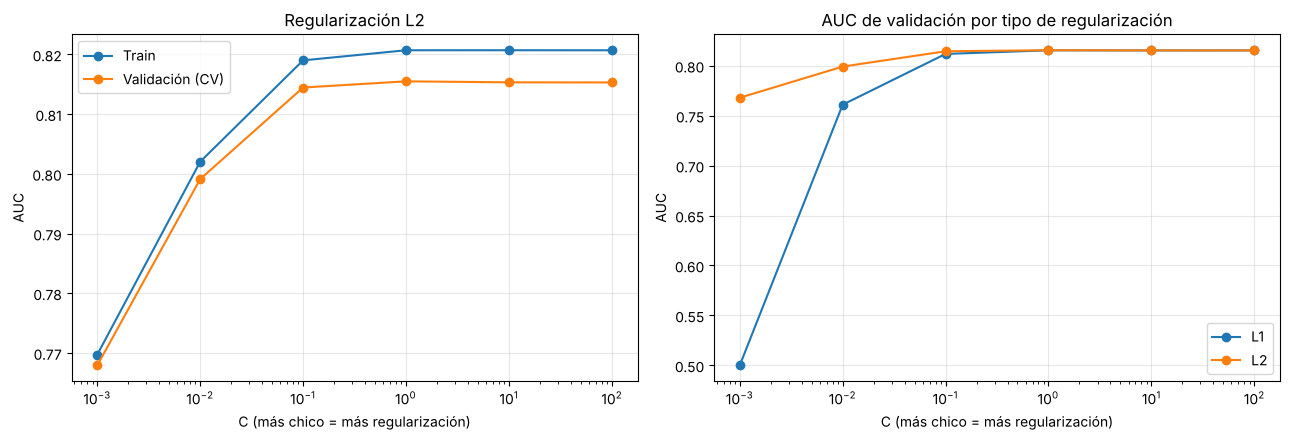

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

l2 = grilla[grilla['regularizacion'] == 'l2'].sort_values('C')
axes[0].plot(l2['C'], l2['auc_train'], 'o-', label='Train')
axes[0].plot(l2['C'], l2['auc'], 'o-', label='Validación (CV)')
axes[0].set_title('Regularización L2')
axes[0].legend()

for regularizacion in GRILLA['regularizacion']:
    sub = grilla[grilla['regularizacion'] == regularizacion].sort_values('C')
    axes[1].plot(sub['C'], sub['auc'], 'o-', label=regularizacion.upper())
axes[1].set_title('AUC de validación por tipo de regularización')
axes[1].legend()

for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('C (más chico = más regularización)')
    ax.set_ylabel('AUC')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Mejor configuración

Se elige la combinación con **mayor AUC de validación**. Si hay otras dentro de un desvío estándar, se muestran para considerar la más simple (más regularizada, o sea con `C` más chico) y la de menor distancia entre train y validación.

In [ ]:
mejor = grilla.iloc[0]
print('Mejor regresión logística:')
print(f"  C={mejor['C']:g}, regularización={mejor['regularizacion']}")
print(f"  AUC validación = {mejor['auc']:.3f} ± {mejor['auc_std']:.3f}")
print(f"  AUC train      = {mejor['auc_train']:.3f}  (diferencia {mejor['auc_train'] - mejor['auc']:.3f})")
print(f"  Diferencia con el baseline: {mejor['auc'] - baseline['auc']:+.3f} de AUC")

empatadas = grilla[grilla['auc'] >= mejor['auc'] - mejor['auc_std']]
print(f"\nCombinaciones dentro de un desvío del mejor: {len(empatadas)}")
empatadas[COLS_TABLA].assign(diferencia_train_val=empatadas['auc_train'] - empatadas['auc']).round(3)

Mejor regresión logística:
  C=1, regularización=l2
  AUC validación = 0.815 ± 0.009
  AUC train      = 0.821  (diferencia 0.005)
  Diferencia con el baseline: +0.000 de AUC

Combinaciones dentro de un desvío del mejor: 8


,C,regularizacion,auc,auc_std,auc_train,accuracy,precision,recall,f1,diferencia_train_val
0,1.0,l2,0.815,0.009,0.821,0.744,0.751,0.721,0.736,0.005
1,1.0,l1,0.815,0.009,0.821,0.743,0.750,0.722,0.735,0.005
2,10.0,l2,0.815,0.009,0.821,0.744,0.750,0.721,0.735,0.005
3,100.0,l2,0.815,0.009,0.821,0.744,0.750,0.722,0.736,0.005
4,100.0,l1,0.815,0.009,0.821,0.744,0.750,0.722,0.735,0.005
5,10.0,l1,0.815,0.009,0.821,0.744,0.750,0.722,0.736,0.005
6,0.1,l2,0.814,0.009,0.819,0.739,0.748,0.711,0.729,0.005
7,0.1,l1,0.812,0.010,0.815,0.745,0.754,0.718,0.735,0.004


**Elección:** `C = 1` con regularización L2. Tiene el mayor AUC de validación (0,815 ± 0,009) y casi no hay diferencia entre train y validación (0,005). Es la misma configuración que el baseline, o sea que la búsqueda no mejora el punto de partida: las 8 combinaciones con `C` ≥ 0,1 quedan dentro de un desvío entre sí, sin importar el tipo de regularización.

La conclusión es distinta a la del árbol. Ahí el problema era el sobreajuste y los hiperparámetros eran clave para controlarlo (+0,10 de AUC). Acá el modelo no sobreajusta, así que regularizarlo no aporta: lo que lo limita es que solo puede representar relaciones lineales.

## 5. Análisis del modelo elegido

Se reconstruye la mejor regresión logística de la grilla y se analiza: matriz de confusión (con las predicciones de validación de la CV) y coeficientes del modelo.

In [ ]:
params_mejor = {'C': float(mejor['C']), 'regularizacion': mejor['regularizacion']}
mejor_logistica = crear_logistica(**params_mejor)
mejor_logistica

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1

### 5.1 Matriz de confusión

Cada película se predice con el modelo del fold en el que quedó en validación (o sea, con un modelo que no la vio al entrenar). Se usa el umbral por defecto de 0,5 sobre la probabilidad.

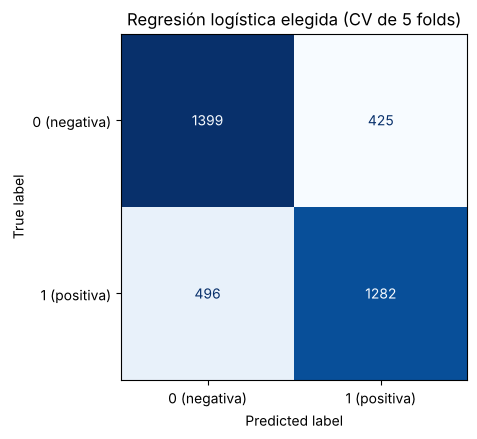

Verdaderos negativos: 1399  | Falsos positivos: 425
Falsos negativos:     496  | Verdaderos positivos: 1282
De las películas con opinión positiva, detecta el 72% (recall)
De las que predice como positivas, acierta el 75% (precision)


In [ ]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = matriz_confusion(mejor_logistica, X, y, titulo='Regresión logística elegida (CV de 5 folds)', ax=ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos: {tn}  | Falsos positivos: {fp}')
print(f'Falsos negativos:     {fn}  | Verdaderos positivos: {tp}')
print(f'De las películas con opinión positiva, detecta el {tp / (tp + fn):.0%} (recall)')
print(f'De las que predice como positivas, acierta el {tp / (tp + fp):.0%} (precision)')

Clasifica bien el 77% de las películas con opinión negativa y el 72% de las positivas. El árbol elegido acertaba el 73% y el 67%, así que la regresión logística mejora en las dos clases. Igual que el árbol, se equivoca un poco más con las positivas (falsos negativos) que con las negativas.

### 5.2 Coeficientes

Son el equivalente a la importancia de variables del árbol, con una ventaja: tienen **signo**. Un coeficiente positivo sube la probabilidad de opinión positiva y uno negativo la baja. Se entrena el modelo con todo el train.

- Las variables numéricas están estandarizadas, así que su coeficiente es el efecto de aumentar la variable en un desvío estándar, y se pueden comparar entre sí.
- En las variables de género, idioma e indicadores, el coeficiente es el efecto de pertenecer a esa categoría.

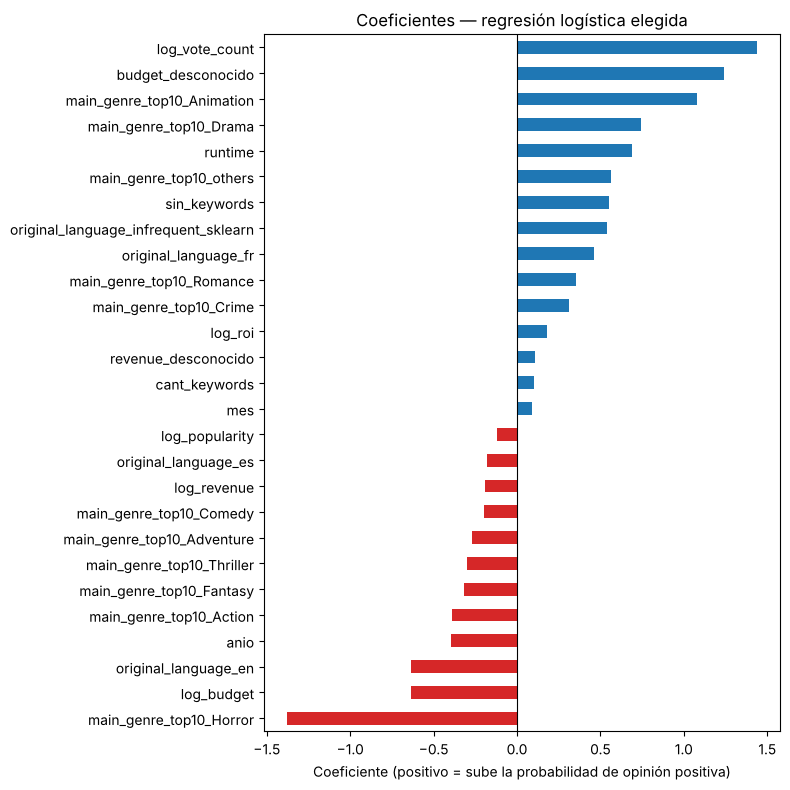

Coeficientes distintos de cero: 27 de 27


log_vote_count                1.436
main_genre_top10_Horror      -1.377
budget_desconocido            1.243
main_genre_top10_Animation    1.077
main_genre_top10_Drama        0.743
runtime                       0.686
log_budget                   -0.636
original_language_en         -0.634
main_genre_top10_others       0.561
sin_keywords                  0.550
dtype: float64

In [ ]:
pipe_mejor = entrenar(mejor_logistica, X, y)
nombres = pipe_mejor.named_steps['prep'].get_feature_names_out()
coeficientes = pd.Series(pipe_mejor.named_steps['modelo'].coef_[0], index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
colores = ['tab:red' if c < 0 else 'tab:blue' for c in coeficientes]
coeficientes.plot.barh(ax=ax, color=colores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Coeficientes — regresión logística elegida')
ax.set_xlabel('Coeficiente (positivo = sube la probabilidad de opinión positiva)')
plt.tight_layout()
plt.show()

print(f'Coeficientes distintos de cero: {(coeficientes != 0).sum()} de {len(coeficientes)}')
mayores = coeficientes.abs().sort_values(ascending=False).index
coeficientes[mayores].head(10).round(3)

**Lectura:**

- **Suben la probabilidad de opinión positiva:** la cantidad de votos (el coeficiente más grande), el presupuesto desconocido, los géneros Animation y Drama, y la duración.
- **La bajan:** el género Horror, un presupuesto alto, el idioma inglés y el año (las películas más nuevas reciben peores opiniones).
- Coincide con el árbol en que la duración, el presupuesto, los votos y los géneros Drama y Horror son relevantes, y agrega en qué sentido actúa cada una.
- El ROI era la segunda variable más importante del árbol, pero acá tiene un coeficiente chico (0,18). Una explicación posible es que su efecto no sea lineal, algo que el árbol puede captar y la regresión logística no.

## 6. Submission y resultado en Kaggle

Se entrena la regresión logística elegida con **todo** el train y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test (no clases 0/1, porque la métrica de la competencia es AUC). El archivo queda en `kaggle/submission_logistica.csv`.

In [ ]:
sub = generar_submission(mejor_logistica, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_logistica.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
assert len(sub) == len(X_test) and sub['opinion'].notna().all()
print(f"Probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
      f"{sub['opinion'].nunique()} valores distintos")
sub.head()

Guardado kaggle/submission_logistica.csv (1201 filas)
Probabilidades entre 0.003 y 0.999, 1201 valores distintos


,id,opinion
0,0,0.885784
1,1,0.435333
2,2,0.655269
3,3,0.757490
4,4,0.622101


### Resultado en Kaggle

*Public Score* obtenido al subir `kaggle/submission_logistica.csv`. La fila se guarda en `resultados/Regresion_Logistica/logistica_final.csv` para la tabla comparativa entre modelos.

In [ ]:
auc_kaggle = 0.81932  # Public Score de Kaggle

resultado_final = {
    'modelo': 'Regresión logística',
    'hiperparametros': f"C={params_mejor['C']:g}, regularizacion={params_mejor['regularizacion']}",
    'auc_cv': mejor['auc'], 'auc_cv_std': mejor['auc_std'], 'auc_train': mejor['auc_train'],
    'accuracy': mejor['accuracy'], 'precision': mejor['precision'], 'recall': mejor['recall'], 'f1': mejor['f1'],
    'auc_kaggle': auc_kaggle,
}
pd.DataFrame([resultado_final]).to_csv(f'{CARPETA_RESULTADOS}/logistica_final.csv', index=False)
pd.DataFrame([resultado_final]).round(3)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
0,Regresión logística,"C=1, regularizacion=l2",0.815,0.009,0.821,0.744,0.751,0.721,0.736,0.819


**Interpretación:** el AUC en Kaggle (0,819) es prácticamente igual al de la validación cruzada (0,815 ± 0,009), y queda dentro de su desvío. Esto indica que:

- La CV volvió a estimar bien el rendimiento sobre datos nuevos, igual que con el árbol (0,769 en CV y 0,771 en Kaggle), lo que refuerza su uso para comparar y elegir modelos.
- La regresión logística no está sobreajustada: generaliza al test igual que a los folds de validación.
- Supera al árbol en unos 0,05 de AUC tanto en CV como en Kaggle (0,819 contra 0,771), así que pasa a ser el resultado a superar con Random Forest, AdaBoost y Gradient Boosting.